# Сравнение SWOW и LWOW

Сравниваем SWOW R1 с **первыми** ассоциациями Llama3 (LWOW R1) на одних и тех же словах. 
https://github.com/LLMWorldOfWords/LWOW/tree/main/LWOW_datasets/processed_datasets


In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
import experiment as exp

SWOW_FILE = Path("SWOW-EN18/strength.SWOW-EN.R1.20180827.csv")
LWOW_FILE = Path("LWOW/FA_Llama3.csv")
WORDS_FILE = Path("words.txt")
N_WORDS = 5000
MODEL = "Llama3"

In [9]:
swow = exp.load_associations(SWOW_FILE)

words = WORDS_FILE.read_text(encoding="utf-8").splitlines()

A_swow = exp.build_matrix(swow, words)
print("Слов:", len(words))
print("Первые 15:", words[:15])
print("Дуг в SWOW:", np.count_nonzero(A_swow))

Слов: 5000
Первые 15: ['money', 'food', 'water', 'car', 'music', 'old', 'sex', 'love', 'dog', 'bird', 'happy', 'red', 'green', 'sad', 'cold']
Дуг в SWOW: 140424


In [10]:
lwow = exp.load_lwow(LWOW_FILE)
print("Различных пар cue → response в LWOW:", len(lwow))
display(lwow.head(10))

Различных пар cue → response в LWOW: 293728


,cue,response,weight
0,a,absorbent,0.03
1,a,abundance,0.01
2,a,acorn,0.01
3,a,acquiesce,0.04
4,a,across,0.01
5,a,aesthetic,0.02
6,a,after,0.01
7,a,again,0.01
8,a,age,0.01
9,a,airplane,0.02


In [11]:
A_lwow = exp.build_matrix(lwow, words)

summary = pd.DataFrame({
    "SWOW": [np.count_nonzero(A_swow), round(A_swow.sum(), 3),
             np.count_nonzero(A_swow.sum(axis=1) == 0)],
    "LWOW": [np.count_nonzero(A_lwow), round(A_lwow.sum(), 3),
             np.count_nonzero(A_lwow.sum(axis=1) == 0)],
}, index=["Число дуг", "Сумма весов", "Строк без исходящих дуг"])
display(summary)

swow_edges = A_swow > 0
lwow_edges = A_lwow > 0
shared = np.count_nonzero(swow_edges & lwow_edges)
union = np.count_nonzero(swow_edges | lwow_edges)
print(f"Общих направленных дуг: {shared}")
print(f"Доля общих среди объединения (Жаккар): {shared / union:.3f}" if union else "Нет дуг")

,SWOW,LWOW
Число дуг,140424.000,62587.00
Сумма весов,4076.107,2419.69
Строк без исходящих дуг,0.000,426.00


Общих направленных дуг: 16237
Доля общих среди объединения (Жаккар): 0.087


проверим, что ассоциации адекватные

In [12]:
def top_answers(A, cue, top=5):
    i = words.index(cue)
    indices = np.argsort(-A[i])
    indices = [j for j in indices if A[i, j] > 0][:top]
    return ", ".join(f"{words[j]} ({A[i,j]:.2f})" for j in indices)

for cue in ["food", "water", "love", "money"]:
    if cue in words:
        print(f"{cue}:")
        print("  Люди: ", top_answers(A_swow, cue))
        print("  Llama3:", top_answers(A_lwow, cue))

food:
  Люди:  eat (0.26), good (0.05), meal (0.05), hungry (0.03), yummy (0.03)
  Llama3: cake (0.05), sandwich (0.05), taco (0.05), burger (0.05), picnic (0.04)
water:
  Люди:  liquid (0.11), wet (0.09), drink (0.09), lake (0.06), swim (0.04)
  Llama3: ocean (0.05), boat (0.05), salty (0.05), blue (0.05), wet (0.05)
love:
  Люди:  heart (0.17), hate (0.15), friendship (0.03), marriage (0.03), you (0.03)
  Llama3: forever (0.08), romantic (0.08), heart (0.05), sweet (0.05), kindness (0.04)
money:
  Люди:  cash (0.26), green (0.08), dollars (0.05), currency (0.05), dollar (0.04)
  Llama3: income (0.05), fortune (0.04), loan (0.04), saving (0.04), bill (0.04)


собственные значения

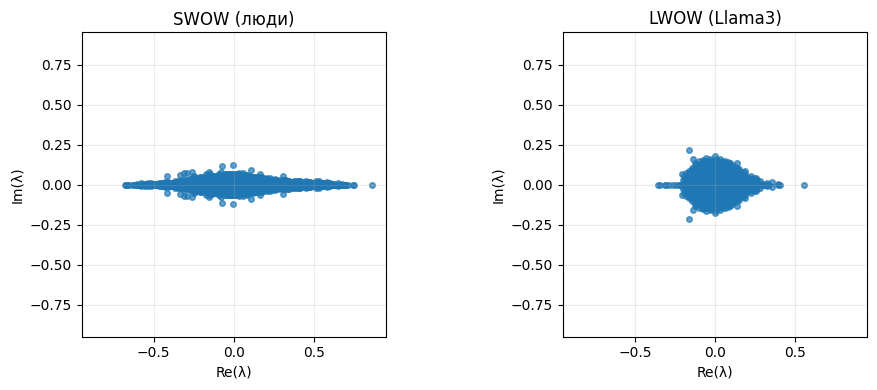

In [13]:
swow_values, swow_vectors = exp.spectrum(A_swow)
lwow_values, lwow_vectors = exp.spectrum(A_lwow)

fig = exp.plot_two_spectra(swow_values, lwow_values, model=MODEL)
fig.savefig("figs/spectra_swow_lwow.png", dpi=180)

ipr для правых собственных векторов

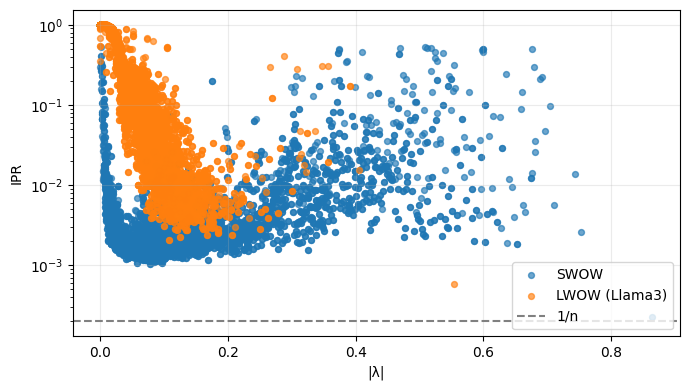

In [14]:
fig = exp.plot_two_ipr(swow_values, swow_vectors, lwow_values, lwow_vectors,
                       model=MODEL)
fig.savefig("figs/ipr_swow_lwow.png", dpi=180)

Сравним по три вектора с наибольшим IPR, оставляя только $|\lambda| > 0.2 max|\lambda|$.

In [15]:
print("SWOW:")
display(exp.localized_words(swow_values, swow_vectors, words,
                            n_vectors=3, n_words=8))

print("LWOW (Llama3):")
display(exp.localized_words(lwow_values, lwow_vectors, words,
                            n_vectors=3, n_words=8))

SWOW:


,lambda,IPR,words
0,-0.509+0.000j,0.5233,"harley, davidson, motorcycle, helmet, native a..."
1,0.512+0.000j,0.5123,"harley, davidson, motorcycle, occasionally, no..."
2,-0.518+0.000j,0.5112,"flora, fauna, plants, prior, before, after, pr..."


LWOW (Llama3):


,lambda,IPR,words
0,-0.289+0.000j,0.4127,"undo, reverse, backward, concave, return, don'..."
1,-0.347+0.000j,0.3089,"delete, eliminate, erase, accuracy, mosquito, ..."
2,-0.357+0.000j,0.3066,"delete, eliminate, erase, accuracy, mosquito, ..."


In [16]:
def spectral_stats(values, vectors):
    ipr = exp.calculate_ipr(vectors)
    mask = np.abs(values) > 0.2 * np.max(np.abs(values))
    return [round(float(np.max(np.abs(values))), 4),
            int(mask.sum()),
            round(float(np.median(ipr[mask])), 4) if mask.any() else np.nan]

stats = pd.DataFrame(
    {"SWOW": spectral_stats(swow_values, swow_vectors),
     "LWOW": spectral_stats(lwow_values, lwow_vectors)},
    index=["Спектральный радиус", "Мод с |λ| > 0.2 max|λ|", "Медиана IPR этих мод"]
)
display(stats)

,SWOW,LWOW
Спектральный радиус,0.8648,0.5548
Мод с |λ| > 0.2 max|λ|,1649.0000,978.0000
Медиана IPR этих мод,0.0054,0.0075
